In [2]:
#problem with previous part was just 1 word for context

In [3]:
# building an mlp

In [4]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [5]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [6]:
len(words)

32033

In [7]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [93]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [94]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [182]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [183]:
len(words)

32033

In [184]:
n1

25626

In [185]:
n2

28829

In [15]:
C = torch.randn((27, 2))

In [23]:
C[5]

tensor([-0.4982, -1.1781])

In [27]:
C[X]

tensor([[[ 0.5261,  0.0520],
         [ 0.5261,  0.0520],
         [ 0.5261,  0.0520]],

        [[ 0.5261,  0.0520],
         [ 0.5261,  0.0520],
         [-0.4982, -1.1781]],

        [[ 0.5261,  0.0520],
         [-0.4982, -1.1781],
         [-0.2250,  0.8619]],

        [[-0.4982, -1.1781],
         [-0.2250,  0.8619],
         [-0.2250,  0.8619]],

        [[-0.2250,  0.8619],
         [-0.2250,  0.8619],
         [-1.7299,  1.0480]],

        [[ 0.5261,  0.0520],
         [ 0.5261,  0.0520],
         [ 0.5261,  0.0520]],

        [[ 0.5261,  0.0520],
         [ 0.5261,  0.0520],
         [-1.4482, -1.5039]],

        [[ 0.5261,  0.0520],
         [-1.4482, -1.5039],
         [-1.9378,  2.4480]],

        [[-1.4482, -1.5039],
         [-1.9378,  2.4480],
         [-0.5611, -0.3787]],

        [[-1.9378,  2.4480],
         [-0.5611, -0.3787],
         [-0.5731, -1.0595]],

        [[-0.5611, -0.3787],
         [-0.5731, -1.0595],
         [-0.5611, -0.3787]],

        [[-0.5731, -1

In [28]:
X[13, 2]

tensor(1)

In [29]:
C[X][13, 2]

tensor([-1.7299,  1.0480])

In [ ]:
emb = C[X] # inputs
emb.shape

torch.Size([32, 3, 2])

In [32]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [35]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape 

torch.Size([32, 6])

In [38]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [39]:
a = torch.arange(18)
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [40]:
a.shape

torch.Size([18])

In [43]:
a.view(3, 3, 2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [44]:
a.storage()

/var/folders/jv/fs_lcs7n0bv78hbvsqq84zvc0000gn/T/ipykernel_95931/214256462.py:1: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [45]:
emb.shape

torch.Size([32, 3, 2])

In [46]:
emb.view(32, 6)

tensor([[ 0.5261,  0.0520,  0.5261,  0.0520,  0.5261,  0.0520],
        [ 0.5261,  0.0520,  0.5261,  0.0520, -0.4982, -1.1781],
        [ 0.5261,  0.0520, -0.4982, -1.1781, -0.2250,  0.8619],
        [-0.4982, -1.1781, -0.2250,  0.8619, -0.2250,  0.8619],
        [-0.2250,  0.8619, -0.2250,  0.8619, -1.7299,  1.0480],
        [ 0.5261,  0.0520,  0.5261,  0.0520,  0.5261,  0.0520],
        [ 0.5261,  0.0520,  0.5261,  0.0520, -1.4482, -1.5039],
        [ 0.5261,  0.0520, -1.4482, -1.5039, -1.9378,  2.4480],
        [-1.4482, -1.5039, -1.9378,  2.4480, -0.5611, -0.3787],
        [-1.9378,  2.4480, -0.5611, -0.3787, -0.5731, -1.0595],
        [-0.5611, -0.3787, -0.5731, -1.0595, -0.5611, -0.3787],
        [-0.5731, -1.0595, -0.5611, -0.3787, -1.7299,  1.0480],
        [ 0.5261,  0.0520,  0.5261,  0.0520,  0.5261,  0.0520],
        [ 0.5261,  0.0520,  0.5261,  0.0520, -1.7299,  1.0480],
        [ 0.5261,  0.0520, -1.7299,  1.0480, -0.5731, -1.0595],
        [-1.7299,  1.0480, -0.5731, -1.0

In [50]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # hidden activation layer

In [51]:
h

tensor([[-0.6883, -0.9992, -0.6227,  ..., -0.4305, -0.8286, -0.9383],
        [-0.9859, -0.9968,  0.6136,  ..., -0.9906,  0.9177, -0.9256],
        [-0.1657, -0.9677,  0.6628,  ...,  0.1127, -0.4478, -0.9467],
        ...,
        [ 0.9818,  0.8277, -0.9422,  ...,  0.0388, -0.9999, -0.9991],
        [-0.8754, -0.9702, -0.9013,  ..., -0.9679, -0.5132,  0.0183],
        [ 0.9765,  0.5186, -0.9458,  ..., -0.9304,  0.9632, -0.5684]])

In [52]:
h.shape

torch.Size([32, 100])

In [53]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [54]:
logits = h @ W2 + b2

In [55]:
logits.shape

torch.Size([32, 27])

In [56]:
logits

tensor([[-2.5481e+00,  3.7404e+00, -8.3694e+00, -1.0794e+01, -6.9545e+00,
          8.7772e+00, -1.4131e+01,  5.2288e-01,  1.8874e+00, -1.3911e+01,
         -5.0617e+00, -7.1533e-02,  4.6715e+00, -1.5536e-01,  9.8274e+00,
          1.1982e+01,  6.4510e+00,  9.6373e+00,  4.5271e+00, -3.1175e+00,
         -6.4280e+00,  3.5930e+00, -1.1229e+00,  7.0979e+00, -5.6974e+00,
         -9.6860e+00, -1.2250e+00],
        [-9.8587e-01,  1.7677e+00,  1.8489e+00, -5.3739e-01, -5.2362e+00,
          3.4256e-01, -2.0937e+01,  5.4381e+00,  7.8660e+00, -6.1896e+00,
          5.0541e+00,  9.4827e+00, -7.3092e+00,  5.4374e+00,  1.1610e+01,
          1.3702e+01,  1.3179e+00, -2.2217e+00,  4.6207e+00,  1.7164e+00,
         -8.1438e+00, -5.3663e+00,  1.1099e+01,  7.8068e+00, -8.1502e+00,
          6.1803e+00,  7.9993e+00],
        [ 2.0741e+00, -2.1074e+00, -1.0607e+00, -7.0037e+00, -2.4701e-01,
          1.4378e+01, -5.7537e+00, -4.2065e+00,  9.8925e-01,  1.7796e+00,
         -6.6282e+00,  4.0017e+00, -7.08

In [63]:
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)
prob.shape

torch.Size([32, 27])

In [67]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(15.4015)

In [68]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [69]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [122]:
# ------------ neater version ---------------

In [246]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [247]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [248]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [249]:
for p in parameters:
    p.requires_grad = True

In [250]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre


In [251]:
lri = []
lossi = []
stepi = []

In [252]:



for i in range(200000):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # (32 3 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # hidden activation layer
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
   # print(loss.item())
    

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = 0.1 if i < 10000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
 #   lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())


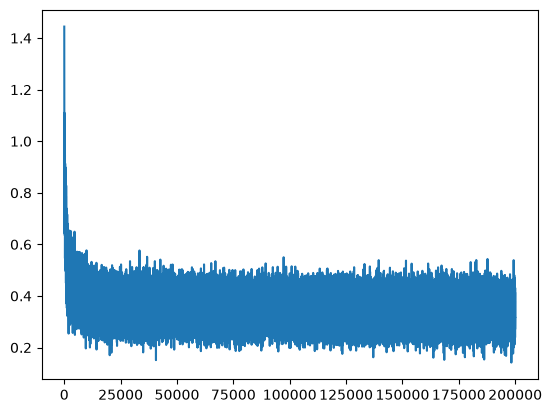

In [253]:
plt.plot(stepi, lossi)

In [199]:
print(loss.item())

2.387334108352661


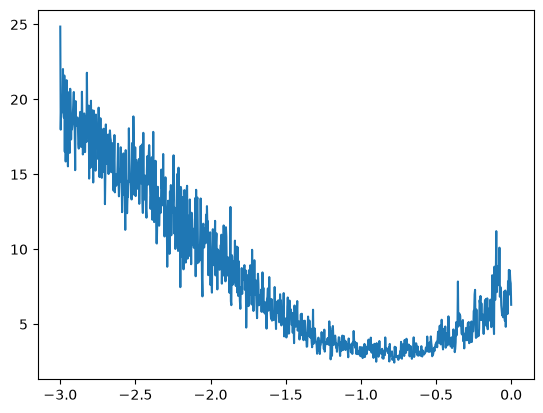

In [153]:
plt.plot(lri, lossi)

In [254]:
emb = C[Xtr] # (32 3 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # hidden activation layer
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.2372, grad_fn=<NllLossBackward0>)

In [255]:
emb = C[Xdev] # (32 3 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # hidden activation layer
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2522, grad_fn=<NllLossBackward0>)

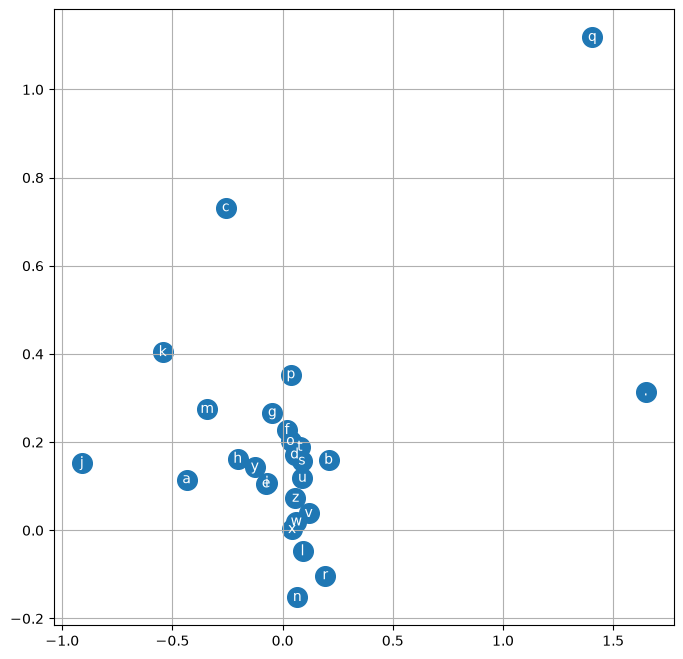

In [256]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [ ]:
# training split, dev/validation split, test split
# 80%, 10%, 10%

In [257]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [258]:

# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
amelle.
khi.
mili.
thay.
skanstee.
mahete.
den.
ara.
kaeli.
nelaniahceaiir.
kaleigh.
ham.
jore.
quinn.
sroel.
alia.
bici.
jero.
dearyni.
